In [38]:
### Cell 1 — Mengimpor library dan membaca dataset

# Mengimpor library yang dibutuhkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Mengatur tampilan agar tabel lebih mudah dibaca
pd.set_option('display.max_columns', None)

# Membaca file Excel
df_mentah = pd.read_excel('/content/case9_student_performance.xlsx')

# Menampilkan lima baris pertama
df_mentah.head()


,student_id,usia,jenis_kelamin,jenis_sekolah,pendidikan_orang_tua,pekerjaan_orang_tua,jam_belajar_per_minggu,persentase_kehadiran,ikut_ekskul,akses_internet,les_privat,waktu_tempuh_menit,nilai_matematika,nilai_bahasa_indonesia,nilai_ipa,nilai_ips,nilai_bahasa_inggris,nilai_rata_rata,status_kelulusan
0,STU0001,17.0,Laki-laki,Negeri,S1,PNS,13.0,59.8,Ya,Ya,Ya,138.0,65.0,68.0,44.0,41.0,43.0,52.2,Tidak Lulus
1,STU0002,13.0,Perempuan,Swasta,S2,PNS,11.0,84.8,Ya,Ya,Tidak,65.0,70.0,79.0,54.0,67.0,NaN,64.0,Tidak Lulus
2,STU0003,12.0,Perempuan,Swasta,S1,NaN,4.0,72.0,Tidak,Ya,Tidak,90.0,41.0,53.0,35.0,38.0,NaN,41.6,Tidak Lulus
3,STU0004,12.0,Laki-laki,Swasta,S1,PNS,26.0,73.4,Ya,Ya,NaN,56.0,87.0,73.0,81.0,76.0,52.0,73.8,Lulus
4,STU0005,13.0,Laki-laki,Swasta,SD,PNS,10.0,94.5,Tidak,Ya,Ya,109.0,71.0,75.0,NaN,72.0,74.0,69.8,Lulus


In [39]:
### Cell 2 — Memeriksa ukuran dataset
print("Jumlah baris dan kolom:")
print(df_mentah.shape)

print("\nJumlah baris:")
print(len(df_mentah))

print("\nNama kolom:")
print(df_mentah.columns.tolist())


Jumlah baris dan kolom:
(800, 19)

Jumlah baris:
800

Nama kolom:
['student_id', 'usia', 'jenis_kelamin', 'jenis_sekolah', 'pendidikan_orang_tua', 'pekerjaan_orang_tua', 'jam_belajar_per_minggu', 'persentase_kehadiran', 'ikut_ekskul', 'akses_internet', 'les_privat', 'waktu_tempuh_menit', 'nilai_matematika', 'nilai_bahasa_indonesia', 'nilai_ipa', 'nilai_ips', 'nilai_bahasa_inggris', 'nilai_rata_rata', 'status_kelulusan']


In [40]:
### Cell 3 — Memeriksa tipe data

df_mentah.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   student_id              800 non-null    object 
 1   usia                    778 non-null    float64
 2   jenis_kelamin           776 non-null    object 
 3   jenis_sekolah           779 non-null    object 
 4   pendidikan_orang_tua    773 non-null    object 
 5   pekerjaan_orang_tua     777 non-null    object 
 6   jam_belajar_per_minggu  773 non-null    float64
 7   persentase_kehadiran    774 non-null    float64
 8   ikut_ekskul             766 non-null    object 
 9   akses_internet          757 non-null    object 
 10  les_privat              776 non-null    object 
 11  waktu_tempuh_menit      770 non-null    float64
 12  nilai_matematika        768 non-null    float64
 13  nilai_bahasa_indonesia  769 non-null    float64
 14  nilai_ipa               757 non-null    fl

In [41]:
### Cell 4 — Statistik deskriptif
df_mentah.describe()
df_mentah.describe(include='object')


,student_id,jenis_kelamin,jenis_sekolah,pendidikan_orang_tua,pekerjaan_orang_tua,ikut_ekskul,akses_internet,les_privat,status_kelulusan
count,800,776,779,773,777,766,757,776,800
unique,800,2,2,5,6,2,2,2,2
top,STU0001,Laki-laki,Negeri,SMP,PNS,Tidak,Ya,Tidak,Lulus
freq,1,399,394,168,152,396,535,509,493


In [42]:
### Cell 5 — Pemeriksaan duplikat

print("Jumlah seluruh baris:", len(df_mentah))

print(
    "Jumlah baris duplikat:",
    df_mentah.duplicated().sum()
)

print(
    "Jumlah student_id duplikat:",
    df_mentah['student_id'].duplicated().sum()
)

Jumlah seluruh baris: 800
Jumlah baris duplikat: 0
Jumlah student_id duplikat: 0


In [43]:
### Cell 6 — Pemeriksaan missing value

missing = df_mentah.isnull().sum()

tabel_missing = pd.DataFrame({
    'kolom': missing.index,
    'jumlah_missing': missing.values,
    'persentase_missing': (
        missing.values / len(df_mentah) * 100
    ).round(2)
})

tabel_missing = tabel_missing.sort_values(
    'jumlah_missing',
    ascending=False
)

tabel_missing

,kolom,jumlah_missing,persentase_missing
16,nilai_bahasa_inggris,48,6.00
9,akses_internet,43,5.38
14,nilai_ipa,43,5.38
8,ikut_ekskul,34,4.25
12,nilai_matematika,32,4.00
15,nilai_ips,31,3.88
13,nilai_bahasa_indonesia,31,3.88
11,waktu_tempuh_menit,30,3.75
6,jam_belajar_per_minggu,27,3.38
4,pendidikan_orang_tua,27,3.38


In [44]:
### Cell 7 — Melihat ringkasan nilai numerik
kolom_numerik = [
    'usia',
    'jam_belajar_per_minggu',
    'persentase_kehadiran',
    'waktu_tempuh_menit',
    'nilai_matematika',
    'nilai_bahasa_indonesia',
    'nilai_ipa',
    'nilai_ips',
    'nilai_bahasa_inggris',
    'nilai_rata_rata'
]

df_mentah[kolom_numerik].describe().T

,count,mean,std,min,25%,50%,75%,max
usia,778.0,14.840617,2.046511,12.0,13.0,15.00,17.00,18.0
jam_belajar_per_minggu,773.0,21.513583,12.156850,1.0,11.0,21.00,32.00,42.0
persentase_kehadiran,774.0,71.814212,15.866712,45.0,57.3,71.65,85.20,99.8
waktu_tempuh_menit,770.0,77.071429,41.519906,5.0,40.0,78.50,113.75,150.0
nilai_matematika,768.0,71.006510,19.902335,18.0,56.0,72.00,87.00,100.0
nilai_bahasa_indonesia,769.0,75.600780,18.991515,31.0,61.0,77.00,94.00,100.0
nilai_ipa,757.0,68.597094,20.438452,13.0,53.0,70.00,85.00,100.0
nilai_ips,769.0,73.109233,20.058730,11.0,59.0,74.00,90.00,100.0
nilai_bahasa_inggris,752.0,67.128989,22.223969,0.0,51.0,70.00,86.00,100.0
nilai_rata_rata,775.0,70.695484,18.463492,25.6,55.9,71.60,86.40,100.0


In [45]:
# Membuat salinan agar data asli tidak berubah
df_bersih = df_mentah.copy()

print("Jumlah baris sebelum dibersihkan:", len(df_bersih))

Jumlah baris sebelum dibersihkan: 800


In [46]:
# Menghapus baris yang memiliki student_id duplikat
df_bersih = df_bersih.drop_duplicates(
    subset='student_id',
    keep='first'
)

print("Jumlah baris setelah menghapus duplikat:", len(df_bersih))

Jumlah baris setelah menghapus duplikat: 800


In [47]:
# Menentukan kolom numerik dan kategori
kolom_numerik = df_bersih.select_dtypes(
    include='number'
).columns.tolist()

kolom_kategori = df_bersih.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

# Mengisi missing value pada kolom numerik dengan median
for kolom in kolom_numerik:
    median_kolom = df_bersih[kolom].median()
    df_bersih[kolom] = df_bersih[kolom].fillna(median_kolom)

# Mengisi missing value pada kolom kategori dengan modus
for kolom in kolom_kategori:
    modus_kolom = df_bersih[kolom].mode()

    if not modus_kolom.empty:
        df_bersih[kolom] = df_bersih[kolom].fillna(
            modus_kolom.iloc[0]
        )

print("Total missing value setelah pengisian:")
print(df_bersih.isnull().sum().sum())

Total missing value setelah pengisian:
0


In [48]:
# Memilih kolom numerik yang akan diperiksa
kolom_outlier = [
    'usia',
    'jam_belajar_per_minggu',
    'persentase_kehadiran',
    'waktu_tempuh_menit',
    'nilai_matematika',
    'nilai_bahasa_indonesia',
    'nilai_ipa',
    'nilai_ips',
    'nilai_bahasa_inggris',
    'nilai_rata_rata'
]

# Menghitung batas IQR untuk setiap kolom berdasarkan jenis sekolah
for kolom in kolom_outlier:

    q1 = df_bersih.groupby(
        'jenis_sekolah',
        observed=True
    )[kolom].transform(lambda s: s.quantile(0.25))

    q3 = df_bersih.groupby(
        'jenis_sekolah',
        observed=True
    )[kolom].transform(lambda s: s.quantile(0.75))

    iqr = q3 - q1

    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr

    # Membatasi nilai pada batas bawah dan atas
    df_bersih[kolom] = df_bersih[kolom].clip(
        lower=batas_bawah,
        upper=batas_atas,
        axis=0
    )

print("Penanganan outlier selesai.")

# Memastikan usia berisi angka bulat sebelum mengubah tipenya
assert np.allclose(
    df_bersih['usia'],
    df_bersih['usia'].round()
)

df_bersih['usia'] = df_bersih['usia'].astype(int)

print("Tipe data usia:", df_bersih['usia'].dtype)

Penanganan outlier selesai.
Tipe data usia: int64


In [49]:
print("Ukuran data setelah dibersihkan:")
print(df_bersih.shape)

print("\nJumlah missing value:")
print(df_bersih.isnull().sum().sum())

print("\nJumlah student_id duplikat:")
print(df_bersih['student_id'].duplicated().sum())

print("\nLima baris pertama data bersih:")
display(df_bersih.head())

Ukuran data setelah dibersihkan:
(800, 19)

Jumlah missing value:
0

Jumlah student_id duplikat:
0

Lima baris pertama data bersih:


,student_id,usia,jenis_kelamin,jenis_sekolah,pendidikan_orang_tua,pekerjaan_orang_tua,jam_belajar_per_minggu,persentase_kehadiran,ikut_ekskul,akses_internet,les_privat,waktu_tempuh_menit,nilai_matematika,nilai_bahasa_indonesia,nilai_ipa,nilai_ips,nilai_bahasa_inggris,nilai_rata_rata,status_kelulusan
0,STU0001,17,Laki-laki,Negeri,S1,PNS,13.0,59.8,Ya,Ya,Ya,138.0,65.0,68.0,44.0,41.0,43.0,52.2,Tidak Lulus
1,STU0002,13,Perempuan,Swasta,S2,PNS,11.0,84.8,Ya,Ya,Tidak,65.0,70.0,79.0,54.0,67.0,70.0,64.0,Tidak Lulus
2,STU0003,12,Perempuan,Swasta,S1,PNS,4.0,72.0,Tidak,Ya,Tidak,90.0,41.0,53.0,35.0,38.0,70.0,41.6,Tidak Lulus
3,STU0004,12,Laki-laki,Swasta,S1,PNS,26.0,73.4,Ya,Ya,Tidak,56.0,87.0,73.0,81.0,76.0,52.0,73.8,Lulus
4,STU0005,13,Laki-laki,Swasta,SD,PNS,10.0,94.5,Tidak,Ya,Ya,109.0,71.0,75.0,70.0,72.0,74.0,69.8,Lulus


In [50]:
def cek_kualitas(d, kolom_num, kolom_grup, kunci):
    """
    Memeriksa jumlah baris, duplikat, missing value,
    dan outlier IQR berdasarkan kelompok.
    """

    # Menghitung kuartil per kelompok untuk setiap kolom numerik
    outlier_total = 0

    for kolom in kolom_num:

        q1 = d.groupby(
            kolom_grup,
            observed=True
        )[kolom].transform(
            lambda s: s.quantile(0.25)
        )

        q3 = d.groupby(
            kolom_grup,
            observed=True
        )[kolom].transform(
            lambda s: s.quantile(0.75)
        )

        iqr = q3 - q1

        batas_bawah = q1 - 1.5 * iqr
        batas_atas = q3 + 1.5 * iqr

        outlier = (
            (d[kolom] < batas_bawah) |
            (d[kolom] > batas_atas)
        )

        outlier_total += int(outlier.sum())

    return pd.Series({
        'n_baris': len(d),
        'n_duplikat': d.duplicated(subset=kunci).sum(),
        'n_missing': d.isnull().sum().sum(),
        'n_outlier': outlier_total
    })


print("Fungsi cek_kualitas berhasil dibuat.")

Fungsi cek_kualitas berhasil dibuat.


In [51]:
# Kolom numerik yang digunakan dalam audit
kolom_audit = [
    'usia',
    'jam_belajar_per_minggu',
    'persentase_kehadiran',
    'waktu_tempuh_menit',
    'nilai_matematika',
    'nilai_bahasa_indonesia',
    'nilai_ipa',
    'nilai_ips',
    'nilai_bahasa_inggris',
    'nilai_rata_rata'
]

# Membuat tabel perbandingan
laporan = pd.DataFrame({
    'sebelum': cek_kualitas(
        df_mentah,
        kolom_audit,
        'jenis_sekolah',
        'student_id'
    ),
    'sesudah': cek_kualitas(
        df_bersih,
        kolom_audit,
        'jenis_sekolah',
        'student_id'
    )
})

display(laporan)

,sebelum,sesudah
n_baris,800,800
n_duplikat,0,0
n_missing,511,0
n_outlier,1,0


In [52]:
analisis_sekolah = df_bersih.groupby(
    'jenis_sekolah',
    observed=True
).agg(
    jumlah_siswa=('student_id', 'count'),
    rata_rata_nilai=('nilai_rata_rata', 'mean'),
    rata_rata_kehadiran=('persentase_kehadiran', 'mean'),
    rata_rata_jam_belajar=('jam_belajar_per_minggu', 'mean')
).round(2)

display(analisis_sekolah)

,jumlah_siswa,rata_rata_nilai,rata_rata_kehadiran,rata_rata_jam_belajar
jenis_sekolah,,,,
Negeri,415,71.61,71.57,22.18
Swasta,385,69.77,72.06,20.76


In [53]:
persentase_kelulusan = pd.crosstab(
    df_bersih['jenis_sekolah'],
    df_bersih['status_kelulusan'],
    normalize='index'
).mul(100).round(2)

display(persentase_kelulusan)

status_kelulusan,Lulus,Tidak Lulus
jenis_sekolah,,
Negeri,62.65,37.35
Swasta,60.52,39.48


In [54]:
analisis_belajar = df_bersih.groupby(
    'status_kelulusan',
    observed=True
).agg(
    jumlah_siswa=('student_id', 'count'),
    rata_rata_jam_belajar=('jam_belajar_per_minggu', 'mean'),
    rata_rata_kehadiran=('persentase_kehadiran', 'mean'),
    rata_rata_nilai=('nilai_rata_rata', 'mean')
).round(2)

display(analisis_belajar)

,jumlah_siswa,rata_rata_jam_belajar,rata_rata_kehadiran,rata_rata_nilai
status_kelulusan,,,,
Lulus,493,28.68,74.43,82.79
Tidak Lulus,307,9.96,67.59,51.34


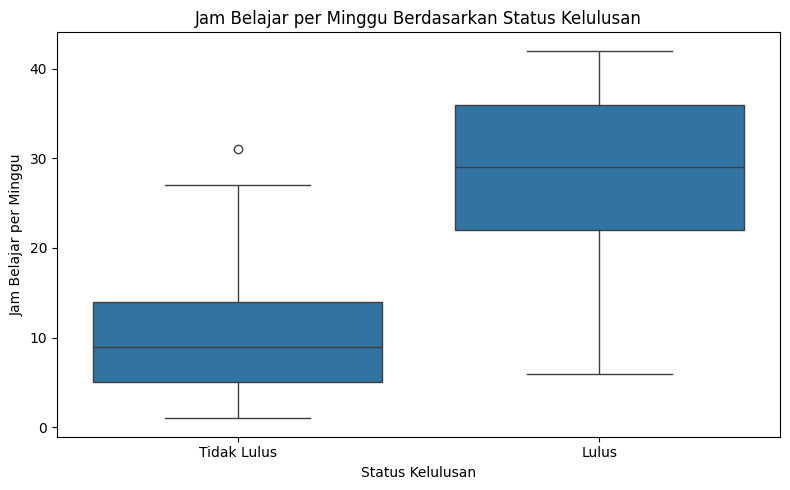

In [55]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_bersih,
    x='status_kelulusan',
    y='jam_belajar_per_minggu'
)

plt.title('Jam Belajar per Minggu Berdasarkan Status Kelulusan')
plt.xlabel('Status Kelulusan')
plt.ylabel('Jam Belajar per Minggu')

plt.tight_layout()
plt.show()

In [56]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [57]:
# Menggunakan data asli dan membuang ID duplikat jika ada
df_model = df_mentah.drop_duplicates(
    subset='student_id',
    keep='first'
).copy()

# Kolom yang akan diprediksi
target = 'status_kelulusan'

# Kolom yang tidak digunakan sebagai fitur
kolom_dikecualikan = [
    'student_id',
    'status_kelulusan',
    'nilai_matematika',
    'nilai_bahasa_indonesia',
    'nilai_ipa',
    'nilai_ips',
    'nilai_bahasa_inggris',
    'nilai_rata_rata'
]

# Membuat X (fitur) dan y (target)
X = df_model.drop(columns=kolom_dikecualikan)
y = df_model[target]

print("Jumlah fitur:", X.shape[1])
print("Jumlah target:", len(y))

print("\nDistribusi target:")
print(y.value_counts())

Jumlah fitur: 11
Jumlah target: 800

Distribusi target:
status_kelulusan
Lulus          493
Tidak Lulus    307
Name: count, dtype: int64


In [58]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 640
Jumlah data testing: 160


In [59]:
# Memisahkan kolom numerik dan kategori
kolom_num_model = X_train.select_dtypes(
    include='number'
).columns.tolist()

kolom_kat_model = X_train.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Kolom numerik:", kolom_num_model)
print("Kolom kategori:", kolom_kat_model)

# Preprocessing kolom numerik
preprocessing_numerik = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocessing kolom kategori
preprocessing_kategori = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Menggabungkan kedua preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('numerik', preprocessing_numerik, kolom_num_model),
    ('kategori', preprocessing_kategori, kolom_kat_model)
])

print("Preprocessor berhasil dibuat.")

Kolom numerik: ['usia', 'jam_belajar_per_minggu', 'persentase_kehadiran', 'waktu_tempuh_menit']
Kolom kategori: ['jenis_kelamin', 'jenis_sekolah', 'pendidikan_orang_tua', 'pekerjaan_orang_tua', 'ikut_ekskul', 'akses_internet', 'les_privat']
Preprocessor berhasil dibuat.


In [60]:
# Membuat pipeline lengkap
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Melatih model hanya menggunakan data training
model.fit(X_train, y_train)

print("Model berhasil dilatih.")

Model berhasil dilatih.


In [61]:
# Membuat prediksi pada data testing
y_pred = model.predict(X_test)

# Menghitung akurasi
akurasi = accuracy_score(y_test, y_pred)

print("Akurasi model:", round(akurasi, 4))

# Menampilkan laporan klasifikasi
print("\nLaporan klasifikasi:")
print(classification_report(y_test, y_pred, zero_division=0))

Akurasi model: 0.9313

Laporan klasifikasi:
              precision    recall  f1-score   support

       Lulus       0.94      0.95      0.94        99
 Tidak Lulus       0.92      0.90      0.91        61

    accuracy                           0.93       160
   macro avg       0.93      0.93      0.93       160
weighted avg       0.93      0.93      0.93       160



In [62]:
import os

# Membuat folder output jika belum tersedia
os.makedirs('output', exist_ok=True)

print("Folder output siap digunakan.")

Folder output siap digunakan.


In [63]:
# Menyimpan dataset yang sudah dibersihkan
df_bersih.to_csv(
    'output/data_bersih.csv',
    index=False
)

print("File data_bersih.csv berhasil disimpan.")

File data_bersih.csv berhasil disimpan.


In [64]:
# Menyiapkan kamus data
kamus_data = pd.DataFrame({
    'kolom': df_bersih.columns,
    'tipe_data': [
        str(tipe) for tipe in df_bersih.dtypes
    ],
    'n_missing': [
        df_bersih[kolom].isnull().sum()
        for kolom in df_bersih.columns
    ],
    'n_unik': [
        df_bersih[kolom].nunique()
        for kolom in df_bersih.columns
    ]
})

display(kamus_data)

# Menyimpan kamus data
kamus_data.to_csv(
    'output/kamus_data.csv',
    index=False
)

print("File kamus_data.csv berhasil disimpan.")

,kolom,tipe_data,n_missing,n_unik
0,student_id,object,0,800
1,usia,int64,0,7
2,jenis_kelamin,object,0,2
3,jenis_sekolah,object,0,2
4,pendidikan_orang_tua,object,0,5
5,pekerjaan_orang_tua,object,0,6
6,jam_belajar_per_minggu,float64,0,42
7,persentase_kehadiran,float64,0,416
8,ikut_ekskul,object,0,2
9,akses_internet,object,0,2


File kamus_data.csv berhasil disimpan.


In [65]:
laporan.to_csv(
    'output/laporan_kualitas.csv',
    index=True
)

print("File laporan_kualitas.csv berhasil disimpan.")

File laporan_kualitas.csv berhasil disimpan.


In [66]:
print("Daftar file dalam folder output:")

for nama_file in os.listdir('output'):
    print(nama_file)

Daftar file dalam folder output:
data_bersih.csv
laporan_kualitas.csv
kamus_data.csv


In [67]:
readme = """
# Tugas Hands-On 3: Pandas Lanjutan

## Dataset
Student Performance.

## Tujuan
Melakukan audit kualitas data, pembersihan data,
analisis eksploratif, dan persiapan model klasifikasi.

## Tahapan
1. Membaca dataset.
2. Memeriksa duplikat, missing value, outlier, dan tipe data.
3. Membersihkan data.
4. Melakukan analisis menggunakan groupby.
5. Membagi data menjadi training dan testing.
6. Melakukan preprocessing menggunakan ColumnTransformer.
7. Melatih dan mengevaluasi model klasifikasi.
8. Menyimpan hasil ke CSV.

## File Output
- output/data_bersih.csv
- output/kamus_data.csv
- output/laporan_kualitas.csv

## Cara Menjalankan
Buka notebook di Google Colab.
Unggah file dataset asli jika diperlukan.
Jalankan setiap cell dari atas ke bawah.

## Catatan
Nilai evaluasi model dan temuan analisis harus
diinterpretasikan berdasarkan hasil aktual notebook.
"""

with open('README.md', 'w', encoding='utf-8') as file:
    file.write(readme.strip())

print("README.md berhasil dibuat.")

README.md berhasil dibuat.


In [68]:
print(df_bersih.dtypes)

student_id                 object
usia                        int64
jenis_kelamin              object
jenis_sekolah              object
pendidikan_orang_tua       object
pekerjaan_orang_tua        object
jam_belajar_per_minggu    float64
persentase_kehadiran      float64
ikut_ekskul                object
akses_internet             object
les_privat                 object
waktu_tempuh_menit        float64
nilai_matematika          float64
nilai_bahasa_indonesia    float64
nilai_ipa                 float64
nilai_ips                 float64
nilai_bahasa_inggris      float64
nilai_rata_rata           float64
status_kelulusan           object
dtype: object
